In [1]:
import numpy as np
import torch
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import torch.nn as nn
import os
from torch.utils.data import DataLoader

In [2]:
if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"
print(f"using device: {device}")

using device: mps


torch.Size([64, 1, 28, 28])
torch.Size([64])
torch.Size([3, 1, 28, 28])
tensor([7, 2, 7])


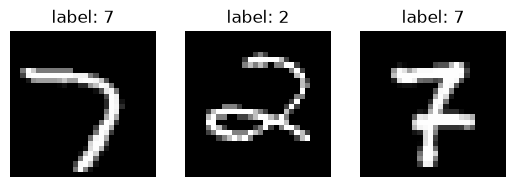

In [3]:
data_dir = os.path.expanduser("~/data")

train_data = datasets.MNIST(
    root=data_dir,
    train=True,
    download=True,
    transform=transforms.ToTensor(),
)
test_data = datasets.MNIST(
    root=data_dir,
    train=False,
    download=True,
    transform=transforms.ToTensor(),
)

train_loader = DataLoader(train_data, batch_size=64, shuffle=True)
test_loader = DataLoader(test_data, batch_size=64, shuffle=True)

images, labels = next(iter(train_loader))
test_images, test_labels = next(iter(test_loader))

print(images.shape)
print(labels.shape)

print(images[:3].shape)
print(labels[:3])

for i in range(3):
    plt.subplot(1, 3, i + 1)
    plt.imshow(images[i].squeeze(), cmap="gray")
    plt.title(f"label: {labels[i].item()}")
    plt.axis("off")
plt.show()

epoch 0: loss 0.12566374242305756
epoch 1: loss 0.2896658778190613
epoch 2: loss 0.346925288438797


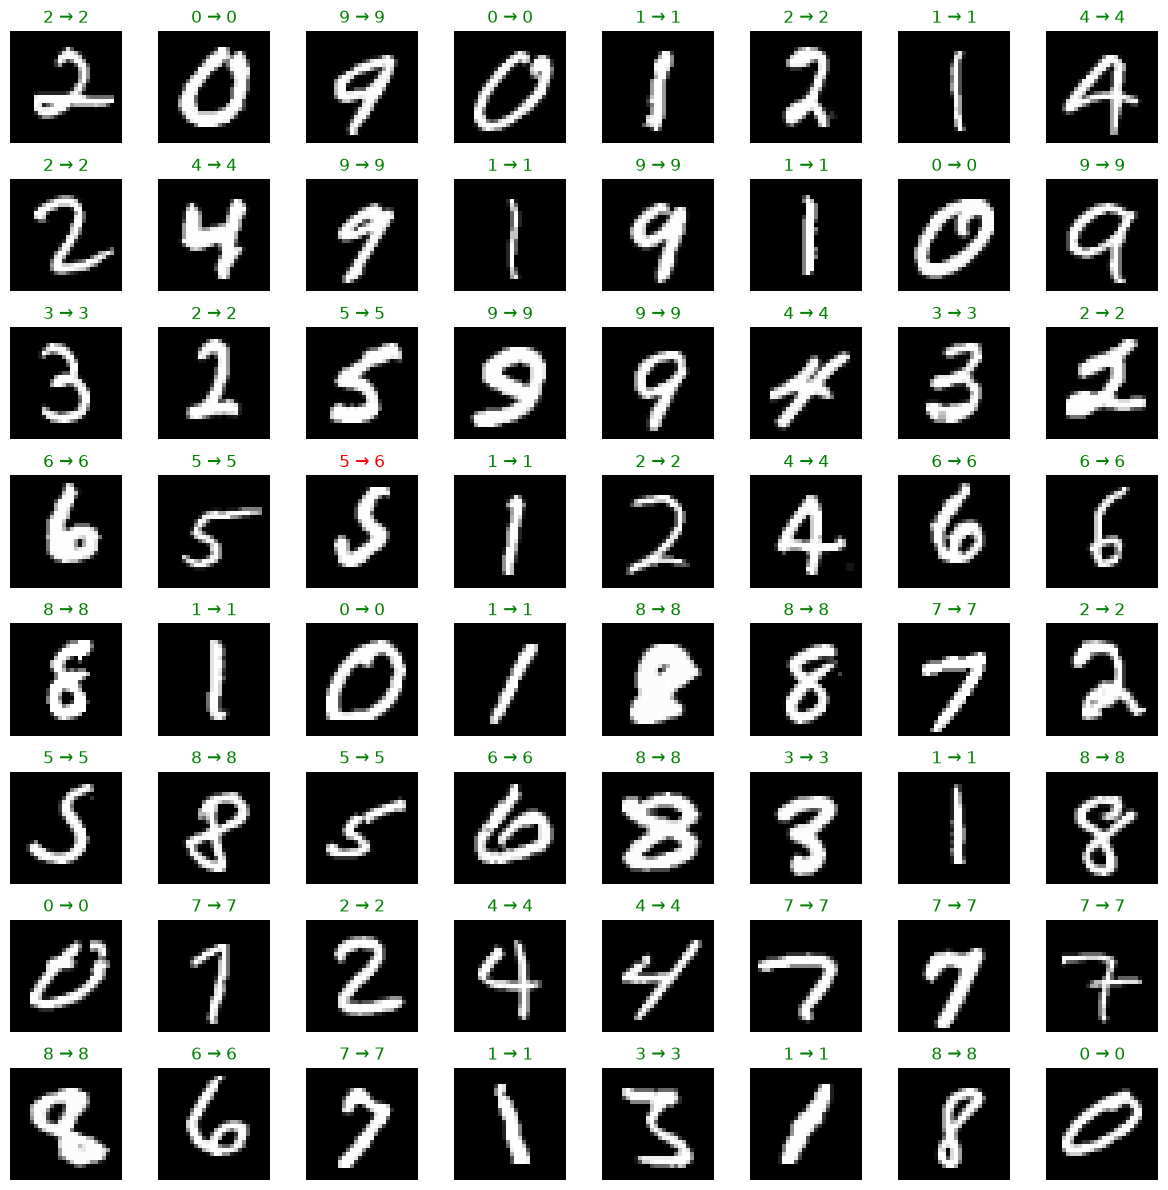

In [4]:
H = 128

model = nn.Sequential(
    nn.Flatten(),
    nn.Linear(784, H),
    nn.ReLU(),
    nn.Linear(H, 10)
)

model.to(device)

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=0.001)

for epoch in range(3):
    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)
        optimizer.zero_grad()
        z = model(images)
        loss = loss_fn(z, labels)
        loss.backward()
        optimizer.step()
    print(f"epoch {epoch}: loss {loss.item()}")

test_images, test_labels = next(iter(test_loader))
with torch.no_grad():
    z = model(test_images.to(device))
    pred = torch.argmax(z, dim=1).cpu()

plt.figure(figsize=(12, 12))
for i in range(64):
    plt.subplot(8, 8, i + 1)
    plt.imshow(test_images[i].squeeze(), cmap="gray")
    if test_labels[i] == pred[i]:
        color = "green"
    else:
        color = "red"
    plt.title(f"{test_labels[i].item()} → {pred[i].item()}", color=color)
    plt.axis("off")
plt.tight_layout()
plt.show()